# Credit Risk Prediction: End-to-End Machine Learning Project

## Tujuan Proyek

Mengembangkan model machine learning untuk memperkirakan risiko kredit peminjam berdasarkan data historis pinjaman. Model akan memprediksi kemungkinan pinjaman mengalami gagal bayar dengan memanfaatkan fitur yang tersedia pada waktu prediksi.

## Metodologi

Proyek ini mengikuti CRISP-DM (*Cross-Industry Standard Process for Data Mining*), yang mencakup pemahaman bisnis, pemahaman data, persiapan data, pemodelan, evaluasi, dan deployment.

## Tools

Python, Pandas, NumPy, Matplotlib, Seaborn, scikit-learn, dan Jupyter Notebook.

## Ruang Lingkup

1. Memahami struktur, karakteristik, dan kualitas data historis pinjaman.
2. Menentukan definisi target risiko kredit berdasarkan status pinjaman.
3. Membersihkan data dan menyiapkan fitur yang relevan.
4. Mencegah data leakage melalui pemeriksaan waktu ketersediaan fitur dan pemisahan data yang tepat.
5. Membangun baseline dan membandingkan beberapa model klasifikasi.
6. Mengevaluasi performa model menggunakan metrik klasifikasi yang sesuai.
7. Menginterpretasikan hasil prediksi dan faktor risiko yang berkontribusi terhadap performa model.
8. Menyiapkan pipeline prediksi yang dapat digunakan kembali.

## Batasan Proyek

- Data yang digunakan merupakan data historis pinjaman periode 2007–2014.
- Model dikembangkan untuk keperluan pembelajaran dan portofolio, bukan langsung untuk keputusan kredit operasional.
- Definisi target, fitur yang digunakan, dan periode evaluasi akan ditetapkan berdasarkan hasil pemeriksaan data.
- Performa pada data historis tidak menjamin performa yang sama pada kondisi kredit saat ini.
- Hasil prediksi menunjukkan estimasi berdasarkan pola historis dan tidak membuktikan hubungan sebab-akibat.

## Step 01: Project Setup & Business Understanding

In [ ]:
# 1.1 Import Libraries & Configuration

# Mengimpor library untuk pengolahan data, visualisasi, dan konfigurasi proyek
from pathlib import Path
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Mengatur tampilan tabel agar pemeriksaan data lebih mudah dibaca
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

# Mengatur tampilan grafik
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# Menampilkan peringatan yang relevan selama proses pengembangan
warnings.filterwarnings("default")

# Menentukan direktori kerja proyek
PROJECT_DIR = Path.cwd()

# Menentukan direktori data sumber yang tetap digunakan
DATA_DIR = PROJECT_DIR / "data"

# Memisahkan folder output dan model untuk versi kedua proyek
OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = PROJECT_DIR / "models"

# Membuat folder output dan model jika belum tersedia
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Menentukan lokasi file input
DATA_FILE = DATA_DIR / "loan_data_2007_2014.csv"
DICTIONARY_FILE = DATA_DIR / "LCDataDictionary.xlsx"

# Menetapkan konfigurasi eksperimen
RANDOM_STATE = 42
PROJECT_NAME = "Credit Risk Prediction"
PROJECT_VERSION = "2.0"

# Menampilkan informasi lingkungan pengembangan
print("=" * 60)
print("KONFIGURASI PROYEK")
print("=" * 60)
print(f"Nama proyek       : {PROJECT_NAME}")
print(f"Versi             : {PROJECT_VERSION}")
print(f"Direktori proyek  : {PROJECT_DIR}")
print(f"Direktori data    : {DATA_DIR}")
print(f"Direktori output  : {OUTPUT_DIR}")
print(f"Direktori model   : {MODEL_DIR}")
print(f"Python            : {sys.version.split()[0]}")
print(f"Pandas            : {pd.__version__}")
print(f"NumPy             : {np.__version__}")
print(f"scikit-learn      : {sklearn.__version__}")
print(f"Random state      : {RANDOM_STATE}")


KONFIGURASI PROYEK
Nama proyek       : Credit Risk Prediction
Versi             : 2.0
Direktori proyek  : d:\Portofolio\Credit Risk Analyst
Direktori data    : d:\Portofolio\Credit Risk Analyst\Data
Direktori output  : d:\Portofolio\Credit Risk Analyst\Outputs v2
Direktori model   : d:\Portofolio\Credit Risk Analyst\Models v2
Python            : 3.12.10
Pandas            : 3.0.6
NumPy             : 2.5.4
scikit-learn      : 1.9.1
Random state      : 42


In [8]:
# 1.2 Validate Project Structure

# Memeriksa keberadaan file input yang diperlukan untuk proyek
required_files = {
    "Dataset pinjaman": DATA_FILE,
    "Metadata dataset": DICTIONARY_FILE,
}

print("=" * 60)
print("VALIDASI FILE INPUT")
print("=" * 60)

missing_files = []

for description, file_path in required_files.items():
    if file_path.is_file():
        print(f"[OK] {description}: {file_path}")
    else:
        print(f"[TIDAK DITEMUKAN] {description}: {file_path}")
        missing_files.append(description)

# Menghentikan proses jika file input wajib belum ditemukan
if missing_files:
    raise FileNotFoundError(
        "File input belum lengkap: "
        + ", ".join(missing_files)
        + ". Periksa kembali nama file dan lokasi folder Data."
    )

# Memastikan direktori penyimpanan tersedia
assert OUTPUT_DIR.is_dir(), "Folder Outputs v2 belum tersedia."
assert MODEL_DIR.is_dir(), "Folder Models v2 belum tersedia."

print("\nValidasi struktur proyek berhasil.")


VALIDASI FILE INPUT
[OK] Dataset pinjaman: d:\Portofolio\Credit Risk Analyst\Data\loan_data_2007_2014.csv
[OK] Metadata dataset: d:\Portofolio\Credit Risk Analyst\Data\LCDataDictionary.xlsx

Validasi struktur proyek berhasil.


In [9]:
# 1.3 Define Initial Business Assumptions

# Mendokumentasikan asumsi bisnis awal sebelum proses analisis data
business_assumptions = {
    "unit_analisis": "Satu baris merepresentasikan satu pinjaman historis.",
    "tujuan_prediksi": (
        "Memperkirakan kemungkinan gagal bayar berdasarkan "
        "fitur yang tersedia pada waktu prediksi."
    ),
    "waktu_prediksi": "Sebelum pinjaman berjalan.",
    "target_awal": {
        "0": "Good Loan",
        "1": "Bad Loan",
    },
    "definisi_target": (
        "Pemetaan status pinjaman akan ditetapkan setelah "
        "pemeriksaan data dan validasi definisi outcome."
    ),
    "strategi_pemisahan_data": (
        "Pemisahan kronologis menjadi train, validation, dan test."
    ),
    "metrik_utama": [
        "ROC-AUC",
        "Average Precision",
    ],
    "metrik_pendukung": [
        "Precision",
        "Recall",
        "F1-score",
        "Confusion Matrix",
        "KS Statistic",
    ],
    "batasan": [
        "Data historis berasal dari periode 2007–2014.",
        "Model ditujukan untuk pembelajaran dan portofolio.",
        "Fitur pascapinjaman tidak digunakan untuk prediksi saat pengajuan.",
        "Performa historis tidak menjamin performa pada kondisi kredit saat ini.",
    ],
}

print("=" * 60)
print("ASUMSI BISNIS AWAL")
print("=" * 60)

for key, value in business_assumptions.items():
    print(f"\n{key.replace('_', ' ').title()}:")

    if isinstance(value, dict):
        for sub_key, sub_value in value.items():
            print(f"  - {sub_key}: {sub_value}")
    elif isinstance(value, list):
        for item in value:
            print(f"  - {item}")
    else:
        print(f"  {value}")


ASUMSI BISNIS AWAL

Unit Analisis:
  Satu baris merepresentasikan satu pinjaman historis.

Tujuan Prediksi:
  Memperkirakan kemungkinan gagal bayar berdasarkan fitur yang tersedia pada waktu prediksi.

Waktu Prediksi:
  Sebelum pinjaman berjalan.

Target Awal:
  - 0: Good Loan
  - 1: Bad Loan

Definisi Target:
  Pemetaan status pinjaman akan ditetapkan setelah pemeriksaan data dan validasi definisi outcome.

Strategi Pemisahan Data:
  Pemisahan kronologis menjadi train, validation, dan test.

Metrik Utama:
  - ROC-AUC
  - Average Precision

Metrik Pendukung:
  - Precision
  - Recall
  - F1-score
  - Confusion Matrix
  - KS Statistic

Batasan:
  - Data historis berasal dari periode 2007–2014.
  - Model ditujukan untuk pembelajaran dan portofolio.
  - Fitur pascapinjaman tidak digunakan untuk prediksi saat pengajuan.
  - Performa historis tidak menjamin performa pada kondisi kredit saat ini.


In [10]:
# 1.4 Save Project Configuration

# Menyimpan konfigurasi proyek agar dapat digunakan kembali
# dan membantu menjaga konsistensi eksperimen
project_config = {
    "project_name": PROJECT_NAME,
    "project_version": PROJECT_VERSION,
    "methodology": "CRISP-DM",
    "project_directory": str(PROJECT_DIR),
    "data_directory": str(DATA_DIR),
    "output_directory": str(OUTPUT_DIR),
    "model_directory": str(MODEL_DIR),
    "dataset_file": DATA_FILE.name,
    "dictionary_file": DICTIONARY_FILE.name,
    "prediction_timing_assumption": "Sebelum pinjaman berjalan",
    "target_definition": {
        "good_loan": 0,
        "bad_loan": 1,
        "status_mapping": "Akan ditetapkan setelah pemeriksaan data",
    },
    "split_strategy": "Chronological train-validation-test split",
    "primary_metrics": [
        "ROC-AUC",
        "Average Precision",
    ],
    "secondary_metrics": [
        "Precision",
        "Recall",
        "F1-score",
        "Confusion Matrix",
        "KS Statistic",
    ],
    "random_state": RANDOM_STATE,
}

config_path = OUTPUT_DIR / "project_config.json"

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(project_config, file, indent=4, ensure_ascii=False)

print("Konfigurasi proyek berhasil disimpan.")
print(f"Lokasi file: {config_path.resolve()}")


Konfigurasi proyek berhasil disimpan.
Lokasi file: D:\Portofolio\Credit Risk Analyst\Outputs v2\project_config.json


In [11]:
# 1.5 Verify Configuration

# Membaca ulang konfigurasi yang telah disimpan untuk memastikan
# file JSON valid dan direktori output sesuai dengan versi kedua
with open(config_path, "r", encoding="utf-8") as file:
    saved_config = json.load(file)

assert saved_config["project_version"] == "2.0"
assert Path(saved_config["output_directory"]) == OUTPUT_DIR
assert Path(saved_config["model_directory"]) == MODEL_DIR
assert config_path.is_file()

print("Verifikasi konfigurasi berhasil.")
print(f"File konfigurasi : {config_path.resolve()}")
print(f"Output disimpan  : {OUTPUT_DIR.resolve()}")
print(f"Model disimpan   : {MODEL_DIR.resolve()}")


Verifikasi konfigurasi berhasil.
File konfigurasi : D:\Portofolio\Credit Risk Analyst\Outputs v2\project_config.json
Output disimpan  : D:\Portofolio\Credit Risk Analyst\Outputs v2
Model disimpan   : D:\Portofolio\Credit Risk Analyst\Models v2


## Step 02: Data Understanding

In [12]:
# 2.1 Load Raw Dataset

# Membaca dataset asli tanpa melakukan perubahan atau penghapusan data
df_raw = pd.read_csv(
    DATA_FILE,
    low_memory=False
)

# Menampilkan ringkasan struktur dataset
print("=" * 60)
print("RINGKASAN DATASET")
print("=" * 60)
print(f"Jumlah baris       : {df_raw.shape[0]:,}")
print(f"Jumlah kolom       : {df_raw.shape[1]:,}")
print(f"Penggunaan memori  : {df_raw.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB")

# Menampilkan lima baris pertama
print("\n" + "=" * 60)
print("CONTOH DATA")
print("=" * 60)
display(df_raw.head())

# Menampilkan nama seluruh kolom
print("\n" + "=" * 60)
print("DAFTAR KOLOM")
print("=" * 60)
for i, column in enumerate(df_raw.columns, start=1):
    print(f"{i:02d}. {column}")


RINGKASAN DATASET
Jumlah baris       : 466,285
Jumlah kolom       : 75
Penggunaan memori  : 779.95 MB

CONTOH DATA


,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
0,0,1077501,1296599,5000,5000,"4,975.0000",36 months,10.6500,162.8700,B,B2,NaN,10+ years,RENT,"24,000.0000",Verified,Dec-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail.action?loan_id=1077501,Borrower added on 12/22/11 > I need to upgrade my business technologies.<br>,credit_card,Computer,860xx,AZ,27.6500,0.0000,Jan-85,1.0000,NaN,NaN,3.0000,0.0000,13648,83.7000,9.0000,f,0.0000,0.0000,"5,861.0714","5,831.7800","5,000.0000",861.0700,0.0000,0.0000,0.0000,Jan-15,171.6200,NaN,Jan-16,0.0000,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1077430,1314167,2500,2500,"2,500.0000",60 months,15.2700,59.8300,C,C4,Ryder,< 1 year,RENT,"30,000.0000",Source Verified,Dec-11,Charged Off,n,https://www.lendingclub.com/browse/loanDetail.action?loan_id=1077430,Borrower added on 12/22/11 > I plan to use this money to finance the motorcycle i am looking a...,car,bike,309xx,GA,1.0000,0.0000,Apr-99,5.0000,NaN,NaN,3.0000,0.0000,1687,9.4000,4.0000,f,0.0000,0.0000,"1,008.7100","1,008.7100",456.4600,435.1700,0.0000,117.0800,1.1100,Apr-13,119.6600,NaN,Sep-13,0.0000,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,1077175,1313524,2400,2400,"2,400.0000",36 months,15.9600,84.3300,C,C5,NaN,10+ years,RENT,"12,252.0000",Not Verified,Dec-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail.action?loan_id=1077175,NaN,small_business,real estate business,606xx,IL,8.7200,0.0000,Nov-01,2.0000,NaN,NaN,2.0000,0.0000,2956,98.5000,10.0000,f,0.0000,0.0000,"3,003.6536","3,003.6500","2,400.0000",603.6500,0.0000,0.0000,0.0000,Jun-14,649.9100,NaN,Jan-16,0.0000,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,1076863,1277178,10000,10000,"10,000.0000",36 months,13.4900,339.3100,C,C1,AIR RESOURCES BOARD,10+ years,RENT,"49,200.0000",Source Verified,Dec-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail.action?loan_id=1076863,"Borrower added on 12/21/11 > to pay for property tax (borrow from friend, need to pay back) & ...",other,personel,917xx,CA,20.0000,0.0000,Feb-96,1.0000,35.0000,NaN,10.0000,0.0000,5598,21.0000,37.0000,f,0.0000,0.0000,"12,226.3022","12,226.3000","10,000.0000","2,209.3300",16.9700,0.0000,0.0000,Jan-15,357.4800,NaN,Jan-15,0.0000,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,1075358,1311748,3000,3000,"3,000.0000",60 months,12.6900,67.7900,B,B5,University Medical Group,1 year,RENT,"80,000.0000",Source Verified,Dec-11,Current,n,https://www.lendingclub.com/browse/loanDetail.action?loan_id=1075358,Borrower added on 12/21/11 > I plan on combining three large interest bills together and freei...,other,Personal,972xx,OR,17.9400,0.0000,Jan-96,0.0000,38.0000,NaN,15.0000,0.0000,27783,53.9000,38.0000,f,766.9000,766.9000,"3,242.1700","3,242.1700","2,233.1000","1,009.0700",0.0000,0.0000,0.0000,Jan-16,67.7900,Feb-16,Jan-16,0.0000,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0000,Na


DAFTAR KOLOM
01. Unnamed: 0
02. id
03. member_id
04. loan_amnt
05. funded_amnt
06. funded_amnt_inv
07. term
08. int_rate
09. installment
10. grade
11. sub_grade
12. emp_title
13. emp_length
14. home_ownership
15. annual_inc
16. verification_status
17. issue_d
18. loan_status
19. pymnt_plan
20. url
21. desc
22. purpose
23. title
24. zip_code
25. addr_state
26. dti
27. delinq_2yrs
28. earliest_cr_line
29. inq_last_6mths
30. mths_since_last_delinq
31. mths_since_last_record
32. open_acc
33. pub_rec
34. revol_bal
35. revol_util
36. total_acc
37. initial_list_status
38. out_prncp
39. out_prncp_inv
40. total_pymnt
41. total_pymnt_inv
42. total_rec_prncp
43. total_rec_int
44. total_rec_late_fee
45. recoveries
46. collection_recovery_fee
47. last_pymnt_d
48. last_pymnt_amnt
49. next_pymnt_d
50. last_credit_pull_d
51. collections_12_mths_ex_med
52. mths_since_last_major_derog
53. policy_code
54. application_type
55. annual_inc_joint
56. dti_joint
57. verification_status_joint
58. acc_now_delin

In [13]:
# 2.2 Inspect Dataset Dictionary

# Membaca metadata yang menjelaskan arti kolom dataset
df_dictionary = pd.read_excel(DICTIONARY_FILE)

# Menampilkan struktur metadata
print("=" * 60)
print("STRUKTUR METADATA DATASET")
print("=" * 60)
print(f"Jumlah baris metadata : {df_dictionary.shape[0]:,}")
print(f"Jumlah kolom metadata : {df_dictionary.shape[1]:,}")
print(f"Nama kolom metadata   : {df_dictionary.columns.tolist()}")

# Menampilkan contoh isi metadata
print("\n" + "=" * 60)
print("CONTOH METADATA")
print("=" * 60)
display(df_dictionary.head(10))

# Memeriksa kolom dataset yang memiliki definisi metadata
# Nama kolom metadata akan diperiksa terlebih dahulu agar tidak mengasumsikan format tertentu
print("\n" + "=" * 60)
print("INFORMASI KOLOM METADATA")
print("=" * 60)
df_dictionary.info()

STRUKTUR METADATA DATASET
Jumlah baris metadata : 98
Jumlah kolom metadata : 3
Nama kolom metadata   : ['Unnamed: 0', 'Description', 'Unnamed: 2']

CONTOH METADATA


,Unnamed: 0,Description,Unnamed: 2
0,_rec,The total amount committed by investors for that loan at that point in time.,Jumlah total yang dilakukan oleh investor untuk pinjaman itu pada saat itu.
1,acc_now_delinq,The number of accounts on which the borrower is now delinquent.,Jumlah akun di mana peminjam sekarang nakal.
2,addr_state,The state provided by the borrower in the loan application,Negara yang disediakan oleh peminjam dalam aplikasi pinjaman
3,all_util,Balance to credit limit on all trades,Saldo ke batas kredit untuk semua perdagangan
4,annual_inc,The self-reported annual income provided by the borrower during registration.,v
5,annual_inc_joint,The combined self-reported annual income provided by the co-borrowers during registration,Penghasilan tahunan yang dilaporkan sendiri gabungan yang disediakan oleh co-peminjam selama pen...
6,application_type,Indicates whether the loan is an individual application or a joint application with two co-borro...,NaN
7,collection_recovery_fee,post charge off collection fee,Biaya pengumpulan biaya pengumpulan pos
8,collections_12_mths_ex_med,Number of collections in 12 months excluding medical collections,Jumlah koleksi dalam 12 bulan tidak termasuk koleksi medis
9,delinq_2yrs,The number of 30+ days past-due incidences of delinquency in the borrower's credit file for the ...,Jumlah 30+ hari insiden kenakalan yang lewat di dalam file kredit peminjam selama 2 tahun terakhir



INFORMASI KOLOM METADATA
<class 'pandas.DataFrame'>
RangeIndex: 98 entries, 0 to 97
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Unnamed: 0   78 non-null     str  
 1   Description  77 non-null     str  
 2   Unnamed: 2   77 non-null     str  
dtypes: str(3)
memory usage: 2.4 KB


In [14]:
# 2.3 Standardize Dataset Dictionary

# Membuat salinan metadata dengan nama kolom yang lebih mudah digunakan
df_dictionary_clean = df_dictionary.iloc[:, :3].copy()

df_dictionary_clean.columns = [
    "feature",
    "description_en",
    "description_id"
]

# Menghapus spasi di awal dan akhir teks pada kolom metadata
for column in ["feature", "description_en", "description_id"]:
    df_dictionary_clean[column] = (
        df_dictionary_clean[column]
        .astype("string")
        .str.strip()
    )

# Menghapus baris yang tidak memiliki nama variabel
df_dictionary_clean = df_dictionary_clean[
    df_dictionary_clean["feature"].notna()
    & (df_dictionary_clean["feature"] != "")
].copy()

# Memeriksa apakah ada nama variabel yang tercatat lebih dari sekali
duplicate_features = df_dictionary_clean[
    df_dictionary_clean["feature"].duplicated(keep=False)
].sort_values("feature")

print("=" * 60)
print("RINGKASAN METADATA")
print("=" * 60)
print(f"Jumlah baris metadata awal     : {len(df_dictionary):,}")
print(f"Jumlah baris setelah dirapikan : {len(df_dictionary_clean):,}")
print(f"Jumlah nama variabel unik      : {df_dictionary_clean['feature'].nunique():,}")
print(f"Jumlah nama variabel duplikat  : {duplicate_features['feature'].nunique():,}")

# Menampilkan metadata untuk variabel penting yang tersedia
important_features = [
    "loan_status",
    "issue_d",
    "loan_amnt",
    "annual_inc",
    "grade",
    "term",
    "recoveries",
    "total_pymnt",
    "last_pymnt_d"
]

display(
    df_dictionary_clean[
        df_dictionary_clean["feature"].isin(important_features)
    ].sort_values("feature")
)

# Menampilkan nama variabel yang tidak ditemukan dalam metadata
dataset_columns = set(df_raw.columns)
dictionary_features = set(df_dictionary_clean["feature"].dropna())

print("\nKolom dataset yang belum ditemukan dalam metadata:")
print(sorted(dataset_columns - dictionary_features))

print("\nNama variabel metadata yang tidak ada dalam dataset:")
print(sorted(dictionary_features - dataset_columns))


RINGKASAN METADATA
Jumlah baris metadata awal     : 98
Jumlah baris setelah dirapikan : 78
Jumlah nama variabel unik      : 77
Jumlah nama variabel duplikat  : 1


,feature,description_en,description_id
4,annual_inc,The self-reported annual income provided by the borrower during registration.,v
19,grade,LC assigned loan grade,LC menugaskan nilai pinjaman
30,issue_d,The month which the loan was funded,Bulan yang didanai pinjaman
35,last_pymnt_d,Last month payment was received,Bulan lalu pembayaran diterima
36,loan_amnt,Last month payment was received,Bulan lalu pembayaran diterima
37,loan_status,Current status of the loan,Status pinjaman saat ini
58,recoveries,Indicates if a payment plan has been put in place for the loan,Menunjukkan jika rencana pembayaran telah diberlakukan untuk pinjaman
62,term,The number of payments on the loan. Values are in months and can be either 36 or 60.,Jumlah pembayaran atas pinjaman. Nilai dalam beberapa bulan dan dapat berupa 36 atau 60.
69,total_pymnt,Payments received to date for total amount funded,Pembayaran diterima hingga saat ini untuk jumlah total yang didanai



Kolom dataset yang belum ditemukan dalam metadata:
['Unnamed: 0', 'dti', 'funded_amnt_inv', 'last_credit_pull_d', 'pymnt_plan', 'verification_status', 'verification_status_joint']

Nama variabel metadata yang tidak ada dalam dataset:
['Femp', 'IDE701782189883', '_rec', 'fico_range_high', 'fico_range_low', 'is_inc_v', 'last_fico_range_high', 'last_fico_range_low', 'verified_status_joint']


In [15]:
# 2.4 Raw Data Quality Assessment

# Memeriksa tipe data, nilai kosong, dan duplikasi pada dataset mentah
missing_summary = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(2),
    "dtype": df_raw.dtypes.astype(str)
})

missing_summary = missing_summary.sort_values(
    by=["missing_count", "missing_pct"],
    ascending=False
)

# Menghitung jumlah baris duplikat secara keseluruhan
duplicate_rows = int(df_raw.duplicated().sum())

# Menghitung kolom yang seluruh nilainya kosong
all_missing_columns = missing_summary[
    missing_summary["missing_pct"] == 100
].index.tolist()

# Menampilkan ringkasan kualitas data
print("=" * 60)
print("RAW DATA QUALITY ASSESSMENT")
print("=" * 60)
print(f"Jumlah baris                  : {len(df_raw):,}")
print(f"Jumlah kolom                  : {df_raw.shape[1]:,}")
print(f"Jumlah baris duplikat         : {duplicate_rows:,}")
print(f"Kolom dengan nilai kosong    : {(df_raw.isna().sum() > 0).sum():,}")
print(f"Kolom yang seluruhnya kosong : {len(all_missing_columns):,}")

# Menampilkan 20 kolom dengan persentase nilai kosong tertinggi
print("\n" + "=" * 60)
print("20 KOLOM DENGAN NILAI KOSONG TERTINGGI")
print("=" * 60)
display(missing_summary.head(20))

# Menampilkan kolom yang seluruh nilainya kosong
print("\n" + "=" * 60)
print("KOLOM YANG SELURUHNYA KOSONG")
print("=" * 60)
print(all_missing_columns)

# Memeriksa duplikasi berdasarkan identifier, tanpa menghapus data
print("\n" + "=" * 60)
print("PEMERIKSAAN IDENTIFIER")
print("=" * 60)

for column in ["id", "member_id"]:
    if column in df_raw.columns:
        print(f"{column}:")
        print(f"  Nilai kosong       : {df_raw[column].isna().sum():,}")
        print(f"  Nilai unik         : {df_raw[column].nunique(dropna=True):,}")
        print(f"  Baris duplikat     : {df_raw[column].duplicated().sum():,}")

RAW DATA QUALITY ASSESSMENT
Jumlah baris                  : 466,285
Jumlah kolom                  : 75
Jumlah baris duplikat         : 0
Kolom dengan nilai kosong    : 40
Kolom yang seluruhnya kosong : 17

20 KOLOM DENGAN NILAI KOSONG TERTINGGI


,missing_count,missing_pct,dtype
annual_inc_joint,466285,100.0000,float64
dti_joint,466285,100.0000,float64
verification_status_joint,466285,100.0000,float64
open_acc_6m,466285,100.0000,float64
open_il_6m,466285,100.0000,float64
open_il_12m,466285,100.0000,float64
open_il_24m,466285,100.0000,float64
mths_since_rcnt_il,466285,100.0000,float64
total_bal_il,466285,100.0000,float64
il_util,466285,100.0000,float64



KOLOM YANG SELURUHNYA KOSONG
['annual_inc_joint', 'dti_joint', 'verification_status_joint', 'open_acc_6m', 'open_il_6m', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m']

PEMERIKSAAN IDENTIFIER
id:
  Nilai kosong       : 0
  Nilai unik         : 466,285
  Baris duplikat     : 0
member_id:
  Nilai kosong       : 0
  Nilai unik         : 466,285
  Baris duplikat     : 0


DISTRIBUSI LOAN STATUS


,loan_status,count,percentage
0,Current,224226,48.0900
1,Fully Paid,184739,39.6200
2,Charged Off,42475,9.1100
3,Late (31-120 days),6900,1.4800
4,In Grace Period,3146,0.6700
5,Does not meet the credit policy. Status:Fully Paid,1988,0.4300
6,Late (16-30 days),1218,0.2600
7,Default,832,0.1800
8,Does not meet the credit policy. Status:Charged Off,761,0.1600



RINGKASAN STATUS
Jumlah status unik : 9
Jumlah status kosong : 0


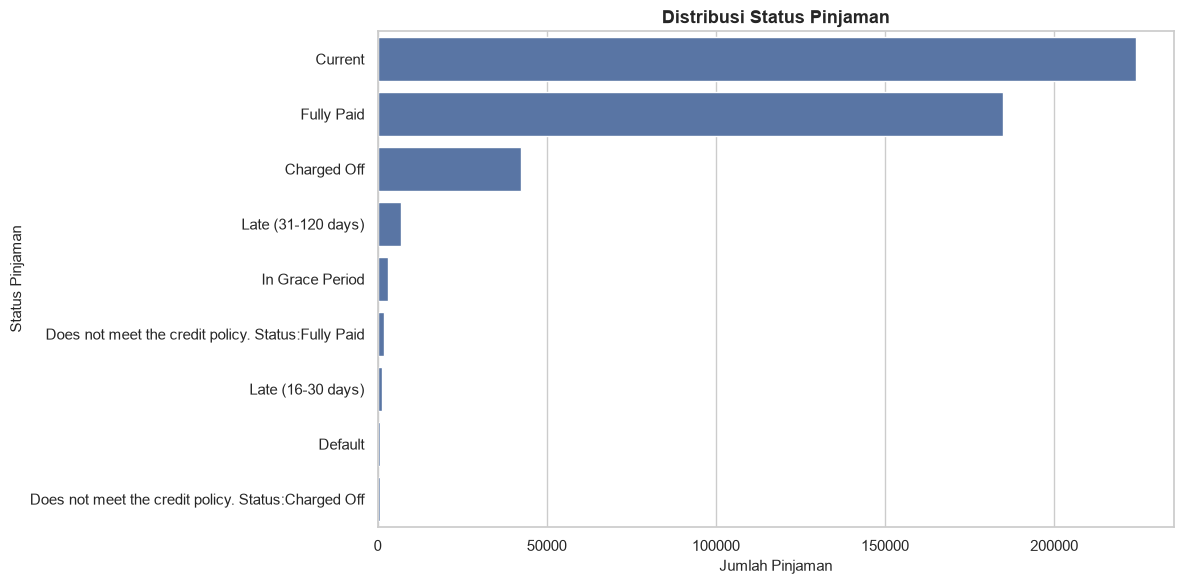

In [16]:
# 2.5 Analyze Loan Status Distribution

# Memeriksa distribusi status pinjaman pada dataset mentah
loan_status_summary = (
    df_raw["loan_status"]
    .value_counts(dropna=False)
    .rename_axis("loan_status")
    .reset_index(name="count")
)

loan_status_summary["percentage"] = (
    loan_status_summary["count"] / len(df_raw) * 100
).round(2)

# Mengurutkan status berdasarkan jumlah data terbanyak
loan_status_summary = loan_status_summary.sort_values(
    "count",
    ascending=False
).reset_index(drop=True)

print("=" * 60)
print("DISTRIBUSI LOAN STATUS")
print("=" * 60)
display(loan_status_summary)

# Menampilkan ringkasan jumlah status yang tersedia
print("\n" + "=" * 60)
print("RINGKASAN STATUS")
print("=" * 60)
print(f"Jumlah status unik : {df_raw['loan_status'].nunique(dropna=True)}")
print(f"Jumlah status kosong : {df_raw['loan_status'].isna().sum():,}")

# Visualisasi distribusi status pinjaman
plt.figure(figsize=(12, 6))
sns.barplot(
    data=loan_status_summary,
    x="count",
    y="loan_status"
)
plt.title("Distribusi Status Pinjaman")
plt.xlabel("Jumlah Pinjaman")
plt.ylabel("Status Pinjaman")
plt.tight_layout()
plt.show()


In [18]:

# 2.6 Inspect Loan Status and Issue Date

# Mengonversi issue_d dari format bulan-tahun, misalnya Dec-11
issue_date_parsed = pd.to_datetime(
    df_raw["issue_d"].astype("string").str.strip(),
    format="%b-%y",
    errors="coerce"
)

# Memeriksa keberhasilan konversi tanggal
print("=" * 60)
print("PEMERIKSAAN ISSUE DATE")
print("=" * 60)
print(f"Jumlah data                 : {len(df_raw):,}")
print(f"Tanggal berhasil dibaca     : {issue_date_parsed.notna().sum():,}")
print(f"Tanggal gagal dibaca        : {issue_date_parsed.isna().sum():,}")
print(f"Tanggal paling awal         : {issue_date_parsed.min()}")
print(f"Tanggal paling akhir        : {issue_date_parsed.max()}")

# Menampilkan nilai asli yang gagal dikonversi untuk investigasi
if issue_date_parsed.isna().any():
    print("\nContoh nilai issue_d yang gagal dikonversi:")
    display(
        df_raw.loc[
            issue_date_parsed.isna(), ["issue_d"]
        ].drop_duplicates().head(10)
    )

# Membuat ringkasan jumlah pinjaman per tahun dan status
status_by_year = pd.DataFrame({
    "issue_year": issue_date_parsed.dt.year,
    "loan_status": df_raw["loan_status"]
})

status_by_year_pivot = pd.crosstab(
    status_by_year["issue_year"],
    status_by_year["loan_status"],
    dropna=False
)

print("\n" + "=" * 60)
print("DISTRIBUSI STATUS PER TAHUN")
print("=" * 60)
display(status_by_year_pivot)

# Menghitung jumlah pinjaman per tahun
yearly_loan_count = (
    issue_date_parsed.dt.year
    .value_counts()
    .sort_index()
    .rename_axis("issue_year")
    .reset_index(name="loan_count")
)

print("\n" + "=" * 60)
print("JUMLAH PINJAMAN PER TAHUN")
print("=" * 60)
display(yearly_loan_count)

# Memastikan hasil konversi dapat digunakan untuk analisis kronologis
assert issue_date_parsed.notna().any(), (
    "Tidak ada tanggal issue_d yang berhasil dikonversi. "
    "Periksa kembali format tanggal."
)




PEMERIKSAAN ISSUE DATE
Jumlah data                 : 466,285
Tanggal berhasil dibaca     : 466,285
Tanggal gagal dibaca        : 0
Tanggal paling awal         : 2007-06-01 00:00:00
Tanggal paling akhir        : 2014-12-01 00:00:00

DISTRIBUSI STATUS PER TAHUN


loan_status,Charged Off,Current,Default,Does not meet the credit policy. Status:Charged Off,Does not meet the credit policy. Status:Fully Paid,Fully Paid,In Grace Period,Late (16-30 days),Late (31-120 days)
issue_year,,,,,,,,,
2007,45,0,0,113,239,206,0,0,0
2008,247,0,0,249,582,1315,0,0,0
2009,594,0,0,129,436,4122,0,0,0
2010,1483,7,1,270,731,10038,0,2,5
2011,3205,1953,8,0,0,16470,28,11,46
2012,8084,3444,28,0,0,41479,83,27,222
2013,14836,60264,182,0,0,56396,977,320,1780
2014,13981,158558,613,0,0,54713,2058,858,4847



JUMLAH PINJAMAN PER TAHUN


,issue_year,loan_count
0,2007,603
1,2008,2393
2,2009,5281
3,2010,12537
4,2011,21721
5,2012,53367
6,2013,134755
7,2014,235628


## Step 03: Data Preparation

In [19]:
# 3.1 Define Target Variable

# Menetapkan pemetaan status pinjaman menjadi target risiko kredit
good_statuses = [
    "Fully Paid",
    "Does not meet the credit policy. Status:Fully Paid"
]

bad_statuses = [
    "Charged Off",
    "Default",
    "Does not meet the credit policy. Status:Charged Off"
]

# Membuat salinan data untuk persiapan pemodelan
df_prepared = df_raw.copy()

# Mengubah status pinjaman menjadi target numerik
df_prepared["target"] = np.select(
    [
        df_prepared["loan_status"].isin(good_statuses),
        df_prepared["loan_status"].isin(bad_statuses)
    ],
    [0, 1],
    default=np.nan
)

# Menyimpan tanggal penerbitan sebagai kolom bantu untuk pembagian data
df_prepared["issue_date"] = issue_date_parsed

# Memisahkan data berlabel dan data yang belum memiliki label final
df_labeled = df_prepared[df_prepared["target"].notna()].copy()
df_unlabeled = df_prepared[df_prepared["target"].isna()].copy()

df_labeled["target"] = df_labeled["target"].astype("int8")

# Menampilkan hasil pelabelan
print("=" * 60)
print("HASIL PENETAPAN TARGET")
print("=" * 60)
print(f"Total data mentah       : {len(df_raw):,}")
print(f"Data berlabel           : {len(df_labeled):,}")
print(f"Data tanpa label final  : {len(df_unlabeled):,}")

target_summary = (
    df_labeled["target"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename(index={0: "Good (0)", 1: "Bad (1)"})
    .rename_axis("target")
    .reset_index(name="count")
)

target_summary["percentage"] = (
    target_summary["count"] / len(df_labeled) * 100
).round(2)

display(target_summary)

print(f"Bad rate: {(df_labeled['target'].mean() * 100):.2f}%")

# Memastikan hanya status yang ditentukan yang menjadi target
assert set(df_labeled["loan_status"].unique()).issubset(
    set(good_statuses + bad_statuses)
)
assert df_labeled["target"].notna().all()


HASIL PENETAPAN TARGET
Total data mentah       : 466,285
Data berlabel           : 230,795
Data tanpa label final  : 235,490


,target,count,percentage
0,Good (0),186727,80.9100
1,Bad (1),44068,19.0900


Bad rate: 19.09%


In [20]:

# 3.2 Select Features and Split Data Chronologically

# Memilih fitur kandidat yang relevan untuk skenario penilaian risiko awal
feature_columns = [
    "loan_amnt",
    "term",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "purpose",
    "addr_state",
    "dti",
    "delinq_2yrs",
    "earliest_cr_line",
    "inq_last_6mths",
    "mths_since_last_delinq",
    "mths_since_last_record",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "initial_list_status",
    "collections_12_mths_ex_med",
    "mths_since_last_major_derog",
    "application_type",
    "acc_now_delinq",
    "tot_coll_amt",
    "tot_cur_bal",
    "total_rev_hi_lim"
]

# Memastikan seluruh fitur tersedia di dataset
missing_features = [
    column for column in feature_columns
    if column not in df_labeled.columns
]

if missing_features:
    raise KeyError(f"Fitur tidak ditemukan: {missing_features}")

# Memastikan data memiliki tanggal untuk pembagian kronologis
df_labeled = df_labeled.dropna(subset=["issue_date"]).copy()

# Membagi dataset berdasarkan bulan penerbitan pinjaman
# Train: sampai Januari 2014
# Validation: Februari sampai Juni 2014
# Test: Juli sampai Desember 2014
train_mask = df_labeled["issue_date"] < "2014-02-01"
validation_mask = (
    (df_labeled["issue_date"] >= "2014-02-01")
    & (df_labeled["issue_date"] < "2014-07-01")
)
test_mask = df_labeled["issue_date"] >= "2014-07-01"

train_df = df_labeled.loc[train_mask].copy()
validation_df = df_labeled.loc[validation_mask].copy()
test_df = df_labeled.loc[test_mask].copy()

# Memastikan pembagian data tidak tumpang tindih
assert len(train_df) + len(validation_df) + len(test_df) == len(df_labeled)
assert train_df["issue_date"].max() < validation_df["issue_date"].min()
assert validation_df["issue_date"].max() < test_df["issue_date"].min()

# Memisahkan fitur dan target pada masing-masing bagian
X_train = train_df[feature_columns].copy()
y_train = train_df["target"].copy()

X_val = validation_df[feature_columns].copy()
y_val = validation_df["target"].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df["target"].copy()

# Menampilkan ringkasan pembagian data
split_summary = pd.DataFrame([
    {
        "dataset": "Train",
        "rows": len(train_df),
        "start_date": train_df["issue_date"].min(),
        "end_date": train_df["issue_date"].max(),
        "bad_rate_pct": y_train.mean() * 100
    },
    {
        "dataset": "Validation",
        "rows": len(validation_df),
        "start_date": validation_df["issue_date"].min(),
        "end_date": validation_df["issue_date"].max(),
        "bad_rate_pct": y_val.mean() * 100
    },
    {
        "dataset": "Test",
        "rows": len(test_df),
        "start_date": test_df["issue_date"].min(),
        "end_date": test_df["issue_date"].max(),
        "bad_rate_pct": y_test.mean() * 100
    }
])

split_summary["bad_rate_pct"] = split_summary["bad_rate_pct"].round(2)

print("=" * 60)
print("RINGKASAN CHRONOLOGICAL SPLIT")
print("=" * 60)
display(split_summary)

print(f"Jumlah fitur kandidat: {len(feature_columns)}")
print(f"Jumlah fitur train   : {X_train.shape[1]}")
print(f"Jumlah target train  : {y_train.shape[0]:,}")


RINGKASAN CHRONOLOGICAL SPLIT


,dataset,rows,start_date,end_date,bad_rate_pct
0,Train,168010,2007-06-01,2014-01-01,18.3200
1,Validation,30680,2014-02-01,2014-06-01,21.7800
2,Test,32105,2014-07-01,2014-12-01,20.5700


Jumlah fitur kandidat: 27
Jumlah fitur train   : 27
Jumlah target train  : 168,010


In [21]:
# 3.3 Build Preprocessing Pipeline

# Mengimpor komponen preprocessing scikit-learn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Mengidentifikasi tipe fitur berdasarkan data train
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Menyiapkan pipeline untuk fitur numerik
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Menyiapkan pipeline untuk fitur kategorikal
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=0.01
    ))
])

# Menggabungkan preprocessing numerik dan kategorikal
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# Fit hanya menggunakan data train
X_train_processed = preprocessor.fit_transform(X_train)

# Validation dan test hanya menjalani transformasi
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Memastikan jumlah baris dan fitur hasil preprocessing konsisten
print("=" * 60)
print("HASIL PREPROCESSING")
print("=" * 60)
print(f"Fitur numerik                  : {len(numeric_features)}")
print(f"Fitur kategorikal              : {len(categorical_features)}")
print(f"Jumlah fitur setelah encoding : {X_train_processed.shape[1]:,}")
print(f"Train shape                    : {X_train_processed.shape}")
print(f"Validation shape               : {X_val_processed.shape}")
print(f"Test shape                     : {X_test_processed.shape}")

assert X_train_processed.shape[0] == len(y_train)
assert X_val_processed.shape[0] == len(y_val)
assert X_test_processed.shape[0] == len(y_test)
assert X_train_processed.shape[1] == X_val_processed.shape[1]
assert X_train_processed.shape[1] == X_test_processed.shape[1]

# Menyimpan ringkasan fitur dan split untuk dokumentasi
preparation_config = {
    "project_version": PROJECT_VERSION,
    "target_column": "target",
    "good_statuses": good_statuses,
    "bad_statuses": bad_statuses,
    "feature_columns": feature_columns,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "split_strategy": "chronological",
    "train_period": "Before 2014-02-01",
    "validation_period": "2014-02-01 to 2014-06-30",
    "test_period": "2014-07-01 onward",
    "random_state": RANDOM_STATE
}

preparation_config_path = OUTPUT_DIR / "preparation_config.json"

with open(preparation_config_path, "w", encoding="utf-8") as file:
    json.dump(preparation_config, file, indent=4, ensure_ascii=False)

print(f"\nKonfigurasi persiapan data disimpan: {preparation_config_path.resolve()}")



HASIL PREPROCESSING
Fitur numerik                  : 18
Fitur kategorikal              : 9
Jumlah fitur setelah encoding : 79
Train shape                    : (168010, 79)
Validation shape               : (30680, 79)
Test shape                     : (32105, 79)

Konfigurasi persiapan data disimpan: D:\Portofolio\Credit Risk Analyst\Outputs v2\preparation_config.json


## Step 04: Modeling

In [22]:
# 4.1 Train and Compare Candidate Models

# Mengimpor model, pipeline, dan metrik evaluasi
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

# Menyiapkan kandidat model dengan konfigurasi yang dapat direproduksi
candidate_models = {
    "Dummy Baseline": DummyClassifier(
        strategy="prior"
    ),
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=50,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

# Melatih dan mengevaluasi setiap model pada validation set
trained_models = {}
validation_results = []
validation_predictions = {}

for model_name, classifier in candidate_models.items():
    print(f"\nMelatih model: {model_name}")

    # Menggabungkan preprocessing dengan classifier
    model_pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    # Melatih model hanya menggunakan data train
    model_pipeline.fit(X_train, y_train)

    # Menghasilkan probabilitas kelas Bad (1)
    y_val_proba = model_pipeline.predict_proba(X_val)[:, 1]

    # Menggunakan threshold awal 0.50 untuk metrik klasifikasi
    y_val_pred = (y_val_proba >= 0.50).astype("int8")

    # Menghitung metrik evaluasi
    result = {
        "model": model_name,
        "roc_auc": roc_auc_score(y_val, y_val_proba),
        "average_precision": average_precision_score(y_val, y_val_proba),
        "precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "f1": f1_score(
            y_val, y_val_pred, zero_division=0
        ),
        "accuracy": accuracy_score(y_val, y_val_pred)
    }

    trained_models[model_name] = model_pipeline
    validation_predictions[model_name] = {
        "probability": y_val_proba,
        "prediction": y_val_pred
    }
    validation_results.append(result)

# Membuat tabel perbandingan model
validation_results_df = pd.DataFrame(validation_results)

validation_results_df = validation_results_df.sort_values(
    by=["average_precision", "roc_auc"],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("PERBANDINGAN MODEL PADA VALIDATION SET")
print("=" * 70)

display(
    validation_results_df.style.format({
        "roc_auc": "{:.4f}",
        "average_precision": "{:.4f}",
        "precision": "{:.2%}",
        "recall": "{:.2%}",
        "f1": "{:.2%}",
        "accuracy": "{:.2%}"
    })
)

# Menampilkan confusion matrix untuk setiap model pada threshold 0.50
for model_name in candidate_models:
    print("\n" + "=" * 60)
    print(f"CONFUSION MATRIX — {model_name}")
    print("=" * 60)

    cm = confusion_matrix(
        y_val,
        validation_predictions[model_name]["prediction"],
        labels=[0, 1]
    )

    cm_df = pd.DataFrame(
        cm,
        index=["Actual Good (0)", "Actual Bad (1)"],
        columns=["Predicted Good (0)", "Predicted Bad (1)"]
    )

    display(cm_df)

# Menyimpan hasil evaluasi validation untuk analisis selanjutnya
validation_results_path = OUTPUT_DIR / "step04_validation_results.csv"

validation_results_df.to_csv(
    validation_results_path,
    index=False
)

print(
    "\nHasil evaluasi validation disimpan di:",
    validation_results_path.resolve()
)



Melatih model: Dummy Baseline

Melatih model: Logistic Regression

Melatih model: Random Forest

PERBANDINGAN MODEL PADA VALIDATION SET


,model,roc_auc,average_precision,precision,recall,f1,accuracy
0,Random Forest,0.6819,0.3652,32.42%,63.49%,42.92%,63.23%
1,Logistic Regression,0.6780,0.3599,31.33%,66.16%,42.52%,61.05%
2,Dummy Baseline,0.5000,0.2178,0.00%,0.00%,0.00%,78.22%



CONFUSION MATRIX — Dummy Baseline


,Predicted Good (0),Predicted Bad (1)
Actual Good (0),23999,0
Actual Bad (1),6681,0



CONFUSION MATRIX — Logistic Regression


,Predicted Good (0),Predicted Bad (1)
Actual Good (0),14311,9688
Actual Bad (1),2261,4420



CONFUSION MATRIX — Random Forest


,Predicted Good (0),Predicted Bad (1)
Actual Good (0),15156,8843
Actual Bad (1),2439,4242



Hasil evaluasi validation disimpan di: D:\Portofolio\Credit Risk Analyst\Outputs v2\step04_validation_results.csv


## Step 05: Evaluation

In [23]:
# 5.1 Optimize Classification Threshold

# Mengimpor fungsi untuk mengevaluasi threshold klasifikasi
from sklearn.metrics import precision_recall_curve, confusion_matrix

# Menetapkan batas recall minimum untuk evaluasi awal
MINIMUM_RECALL = 0.65

# Mengevaluasi threshold untuk model yang lebih baik dari baseline
models_to_evaluate = [
    "Logistic Regression",
    "Random Forest"
]

threshold_results = []
threshold_details = {}

for model_name in models_to_evaluate:
    # Mengambil probabilitas Bad pada validation set
    y_val_proba = validation_predictions[model_name]["probability"]

    # Menghitung precision dan recall pada berbagai threshold
    precisions, recalls, thresholds = precision_recall_curve(
        y_val,
        y_val_proba,
        pos_label=1
    )

    # Precision dan recall memiliki satu elemen tambahan dibanding thresholds
    threshold_table = pd.DataFrame({
        "threshold": thresholds,
        "precision": precisions[:-1],
        "recall": recalls[:-1]
    })

    # Menghitung F1 untuk setiap threshold
    denominator = (
        threshold_table["precision"]
        + threshold_table["recall"]
    )

    threshold_table["f1"] = np.where(
        denominator > 0,
        2 * threshold_table["precision"] * threshold_table["recall"]
        / denominator,
        0
    )

    # Memilih threshold yang memenuhi recall minimum
    eligible_thresholds = threshold_table[
        threshold_table["recall"] >= MINIMUM_RECALL
    ].copy()

    if eligible_thresholds.empty:
        print(
            f"Peringatan: {model_name} tidak memiliki threshold "
            f"yang memenuhi recall >= {MINIMUM_RECALL:.0%}."
        )
        continue

    # Memprioritaskan precision tertinggi, lalu recall dan threshold
    best_threshold_row = (
        eligible_thresholds
        .sort_values(
            ["precision", "recall", "threshold"],
            ascending=[False, False, False]
        )
        .iloc[0]
    )

    selected_threshold = float(best_threshold_row["threshold"])

    # Menghitung prediksi menggunakan threshold terpilih
    y_val_pred = (y_val_proba >= selected_threshold).astype("int8")

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_val_pred,
        labels=[0, 1]
    ).ravel()

    # Menyimpan hasil evaluasi threshold
    threshold_results.append({
        "model": model_name,
        "threshold": selected_threshold,
        "roc_auc": roc_auc_score(y_val, y_val_proba),
        "average_precision": average_precision_score(y_val, y_val_proba),
        "precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "f1": f1_score(
            y_val, y_val_pred, zero_division=0
        ),
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp)
    })

    threshold_details[model_name] = {
        "threshold": selected_threshold,
        "threshold_table": threshold_table,
        "prediction": y_val_pred
    }

# Menampilkan hasil pemilihan threshold
threshold_results_df = pd.DataFrame(threshold_results)

if threshold_results_df.empty:
    raise ValueError(
        "Tidak ada model yang memenuhi kriteria recall minimum."
    )

threshold_results_df = threshold_results_df.sort_values(
    ["average_precision", "roc_auc"],
    ascending=False
).reset_index(drop=True)

print("=" * 70)
print("HASIL OPTIMASI THRESHOLD PADA VALIDATION SET")
print("=" * 70)
print(f"Recall minimum: {MINIMUM_RECALL:.0%}")

display(
    threshold_results_df.style.format({
        "threshold": "{:.4f}",
        "roc_auc": "{:.4f}",
        "average_precision": "{:.4f}",
        "precision": "{:.2%}",
        "recall": "{:.2%}",
        "f1": "{:.2%}"
    })
)

# Memilih model berdasarkan Average Precision, kemudian ROC-AUC
selected_model_name = threshold_results_df.iloc[0]["model"]
selected_threshold = float(
    threshold_results_df.iloc[0]["threshold"]
)

print("\n" + "=" * 70)
print("KANDIDAT MODEL TERPILIH")
print("=" * 70)
print(f"Model     : {selected_model_name}")
print(f"Threshold : {selected_threshold:.4f}")
print(
    "Dasar     : Average Precision tertinggi, "
    "kemudian ROC-AUC, dengan recall memenuhi batas minimum."
)

# Menyimpan hasil threshold dan konfigurasi kandidat
threshold_results_path = OUTPUT_DIR / "step05_threshold_evaluation.csv"
threshold_results_df.to_csv(threshold_results_path, index=False)

selected_model_config = {
    "project_version": PROJECT_VERSION,
    "selected_model": selected_model_name,
    "selected_threshold": selected_threshold,
    "minimum_recall_constraint": MINIMUM_RECALL,
    "selection_metric_priority": [
        "average_precision",
        "roc_auc"
    ],
    "evaluation_dataset": "validation",
    "test_set_used_for_selection": False,
    "random_state": RANDOM_STATE
}

selected_model_config_path = OUTPUT_DIR / "step05_selected_model_config.json"

with open(
    selected_model_config_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        selected_model_config,
        file,
        indent=4,
        ensure_ascii=False
    )

print(f"\nHasil threshold disimpan: {threshold_results_path.resolve()}")
print(f"Konfigurasi model disimpan: {selected_model_config_path.resolve()}")



HASIL OPTIMASI THRESHOLD PADA VALIDATION SET
Recall minimum: 65%


,model,threshold,roc_auc,average_precision,precision,recall,f1,true_negative,false_positive,false_negative,true_positive
0,Random Forest,0.4948,0.6819,0.3652,32.05%,65.05%,42.94%,14783,9216,2335,4346
1,Logistic Regression,0.5053,0.6780,0.3599,31.61%,65.01%,42.54%,14603,9396,2338,4343



KANDIDAT MODEL TERPILIH
Model     : Random Forest
Threshold : 0.4948
Dasar     : Average Precision tertinggi, kemudian ROC-AUC, dengan recall memenuhi batas minimum.

Hasil threshold disimpan: D:\Portofolio\Credit Risk Analyst\Outputs v2\step05_threshold_evaluation.csv
Konfigurasi model disimpan: D:\Portofolio\Credit Risk Analyst\Outputs v2\step05_selected_model_config.json


In [24]:
# 5.2 Final Test Evaluation

# Mengambil model terpilih dan threshold dari hasil validation
final_model = trained_models[selected_model_name]
final_threshold = selected_threshold

# Menghasilkan probabilitas dan prediksi pada test set
y_test_proba = final_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_proba >= final_threshold).astype("int8")

# Menghitung metrik evaluasi final
test_roc_auc = roc_auc_score(y_test, y_test_proba)
test_average_precision = average_precision_score(y_test, y_test_proba)
test_precision = precision_score(y_test, y_test_pred, zero_division=0)
test_recall = recall_score(y_test, y_test_pred, zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, zero_division=0)
test_accuracy = accuracy_score(y_test, y_test_pred)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
).ravel()

# Menyusun hasil evaluasi final
final_test_results = pd.DataFrame([{
    "model": selected_model_name,
    "threshold": final_threshold,
    "test_rows": len(y_test),
    "roc_auc": test_roc_auc,
    "average_precision": test_average_precision,
    "precision": test_precision,
    "recall": test_recall,
    "f1": test_f1,
    "accuracy": test_accuracy,
    "true_negative": int(tn),
    "false_positive": int(fp),
    "false_negative": int(fn),
    "true_positive": int(tp)
}])

print("=" * 70)
print("FINAL TEST EVALUATION")
print("=" * 70)

display(
    final_test_results.style.format({
        "threshold": "{:.4f}",
        "roc_auc": "{:.4f}",
        "average_precision": "{:.4f}",
        "precision": "{:.2%}",
        "recall": "{:.2%}",
        "f1": "{:.2%}",
        "accuracy": "{:.2%}"
    })
)

# Menampilkan confusion matrix
print("\n" + "=" * 70)
print("CONFUSION MATRIX — TEST SET")
print("=" * 70)

test_confusion_matrix = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual Good (0)", "Actual Bad (1)"],
    columns=["Predicted Good (0)", "Predicted Bad (1)"]
)

display(test_confusion_matrix)

# Menyimpan hasil test ke direktori output
final_test_results_path = OUTPUT_DIR / "step05_final_test_results.csv"

final_test_results.to_csv(
    final_test_results_path,
    index=False
)

print(
    "\nHasil evaluasi final disimpan:",
    final_test_results_path.resolve()
)



FINAL TEST EVALUATION


,model,threshold,test_rows,roc_auc,average_precision,precision,recall,f1,accuracy,true_negative,false_positive,false_negative,true_positive
0,Random Forest,0.4948,32105,0.6894,0.3488,30.83%,65.63%,41.95%,62.63%,15772,9728,2270,4335



CONFUSION MATRIX — TEST SET


,Predicted Good (0),Predicted Bad (1)
Actual Good (0),15772,9728
Actual Bad (1),2270,4335



Hasil evaluasi final disimpan: D:\Portofolio\Credit Risk Analyst\Outputs v2\step05_final_test_results.csv


## Step 06: Model Interpretation

PERMUTATION FEATURE IMPORTANCE
Model                  : Random Forest
Metrik                  : Average Precision
Jumlah sampel           : 10,000
Jumlah fitur awal       : 27
Jumlah pengulangan      : 5

15 FITUR PALING PENTING


,feature,importance_mean,importance_std
0,term,0.07423,0.00331
1,annual_inc,0.02584,0.00267
2,dti,0.01652,0.00183
3,revol_util,0.00803,0.00275
4,tot_cur_bal,0.00707,0.00190
5,home_ownership,0.00607,0.00098
6,total_acc,0.00232,0.00075
7,total_rev_hi_lim,0.00225,0.00062
8,verification_status,0.00213,0.00352
9,inq_last_6mths,0.00172,0.00096



Hasil importance disimpan: D:\Portofolio\Credit Risk Analyst\Outputs v2\step06_permutation_importance.csv


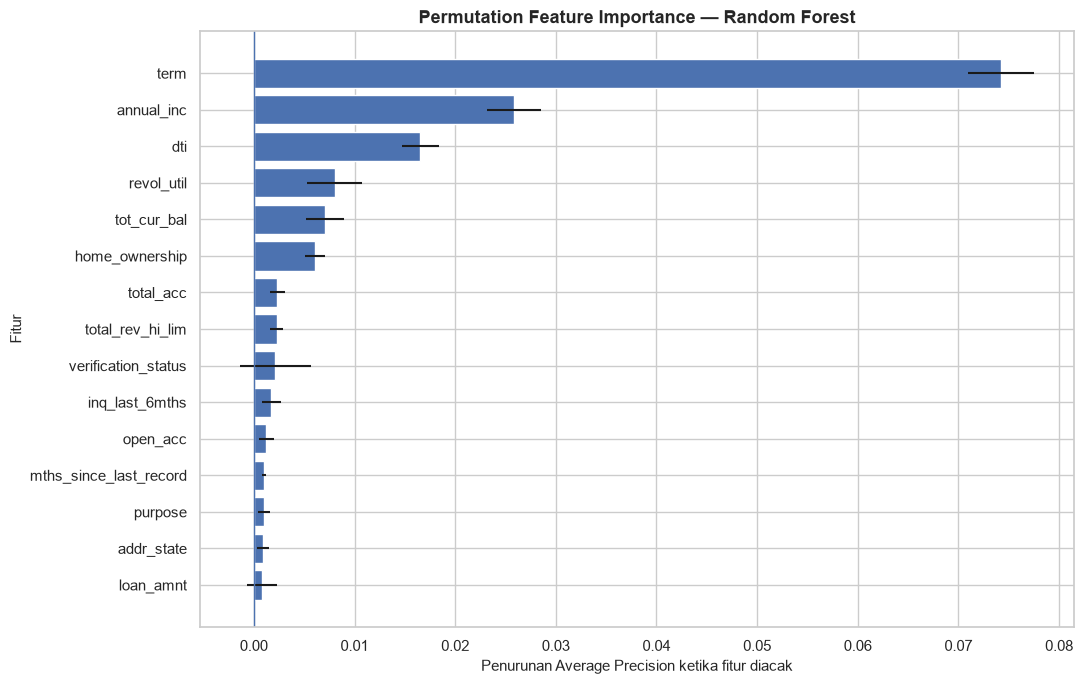


Fitur dengan rata-rata importance negatif:
['collections_12_mths_ex_med', 'mths_since_last_major_derog', 'initial_list_status', 'revol_bal']


In [25]:
# 6.1 Calculate Permutation Feature Importance

# Mengimpor fungsi permutation importance
from sklearn.inspection import permutation_importance

# Mengambil sampel validation secara reproducible untuk efisiensi komputasi
importance_sample_size = min(10_000, len(X_val))

X_importance = X_val.sample(
    n=importance_sample_size,
    random_state=RANDOM_STATE
)

y_importance = y_val.loc[X_importance.index]

print("=" * 70)
print("PERMUTATION FEATURE IMPORTANCE")
print("=" * 70)
print(f"Model                  : {selected_model_name}")
print(f"Metrik                  : Average Precision")
print(f"Jumlah sampel           : {len(X_importance):,}")
print(f"Jumlah fitur awal       : {X_importance.shape[1]}")
print("Jumlah pengulangan      : 5")

# Mengukur penurunan performa saat fitur diacak
importance_result = permutation_importance(
    estimator=final_model,
    X=X_importance,
    y=y_importance,
    scoring="average_precision",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Menyusun hasil kepentingan fitur
feature_importance_df = pd.DataFrame({
    "feature": X_importance.columns,
    "importance_mean": importance_result.importances_mean,
    "importance_std": importance_result.importances_std
})

feature_importance_df = feature_importance_df.sort_values(
    "importance_mean",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("15 FITUR PALING PENTING")
print("=" * 70)

display(
    feature_importance_df.head(15).style.format({
        "importance_mean": "{:.5f}",
        "importance_std": "{:.5f}"
    })
)

# Menyimpan hasil lengkap seluruh fitur
importance_path = OUTPUT_DIR / "step06_permutation_importance.csv"

feature_importance_df.to_csv(
    importance_path,
    index=False
)

print(f"\nHasil importance disimpan: {importance_path.resolve()}")

# Membuat grafik 15 fitur teratas
top_features = feature_importance_df.head(15).sort_values(
    "importance_mean",
    ascending=True
)

plt.figure(figsize=(11, 7))
plt.barh(
    top_features["feature"],
    top_features["importance_mean"],
    xerr=top_features["importance_std"]
)
plt.axvline(0, linewidth=1)
plt.title("Permutation Feature Importance — Random Forest")
plt.xlabel("Penurunan Average Precision ketika fitur diacak")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()

# Menandai fitur yang importance-nya negatif
negative_features = feature_importance_df[
    feature_importance_df["importance_mean"] < 0
]["feature"].tolist()

print("\nFitur dengan rata-rata importance negatif:")
print(negative_features if negative_features else "Tidak ada")


## Step 07: Save Final Model and Configuration

In [26]:
# 7.1 Save Final Model and Configuration

import joblib
from datetime import datetime

# Menentukan lokasi penyimpanan model final
final_model_path = MODEL_DIR / "credit_risk_random_forest_v2.joblib"
final_config_path = MODEL_DIR / "credit_risk_model_config_v2.json"

# Menyimpan pipeline lengkap yang sudah dilatih
# Pipeline mencakup preprocessing dan Random Forest
joblib.dump(final_model, final_model_path)

# Menyiapkan konfigurasi model untuk proses prediksi
final_model_config = {
    "project_name": PROJECT_NAME,
    "project_version": PROJECT_VERSION,
    "model_name": selected_model_name,
    "model_type": "binary_classification",
    "target_column": "target",
    "target_mapping": {
        "0": "Good",
        "1": "Bad"
    },
    "decision_threshold": float(final_threshold),
    "feature_columns": feature_columns,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "training_strategy": "chronological_split",
    "test_metrics": {
        "roc_auc": float(test_roc_auc),
        "average_precision": float(test_average_precision),
        "precision": float(test_precision),
        "recall": float(test_recall),
        "f1": float(test_f1),
        "accuracy": float(test_accuracy)
    },
    "created_at": datetime.now().isoformat(),
    "random_state": RANDOM_STATE
}

# Menyimpan konfigurasi dalam format JSON
with open(final_config_path, "w", encoding="utf-8") as file:
    json.dump(
        final_model_config,
        file,
        indent=4,
        ensure_ascii=False
    )

# Memuat kembali model untuk memastikan artifact valid
loaded_model = joblib.load(final_model_path)

# Memastikan hasil prediksi sebelum dan sesudah penyimpanan identik
sample_data = X_test.head(10)

original_proba = final_model.predict_proba(sample_data)[:, 1]
loaded_proba = loaded_model.predict_proba(sample_data)[:, 1]

np.testing.assert_allclose(original_proba, loaded_proba)

print("=" * 70)
print("MODEL ARTIFACT VERIFICATION")
print("=" * 70)
print(f"Model              : {selected_model_name}")
print(f"Threshold          : {final_threshold:.4f}")
print(f"Jumlah fitur input : {len(feature_columns)}")
print(f"Model tersimpan    : {final_model_path.resolve()}")
print(f"Konfigurasi        : {final_config_path.resolve()}")
print("Verifikasi         : BERHASIL")



MODEL ARTIFACT VERIFICATION
Model              : Random Forest
Threshold          : 0.4948
Jumlah fitur input : 27
Model tersimpan    : D:\Portofolio\Credit Risk Analyst\Models v2\credit_risk_random_forest_v2.joblib
Konfigurasi        : D:\Portofolio\Credit Risk Analyst\Models v2\credit_risk_model_config_v2.json
Verifikasi         : BERHASIL


In [27]:
# 7.2 Create Reusable Prediction Function

# Membaca model dan konfigurasi yang telah disimpan
prediction_model = joblib.load(final_model_path)

with open(final_config_path, "r", encoding="utf-8") as file:
    prediction_config = json.load(file)

def predict_credit_risk(input_data):
    """
    Menghasilkan prediksi risiko kredit menggunakan model tersimpan.

    Parameter
    ---------
    input_data : pandas.DataFrame
        Data peminjam dengan kolom sesuai fitur model.

    Returns
    -------
    pandas.DataFrame
        Skor probabilitas dan klasifikasi risiko.
    """

    # Memastikan input menggunakan DataFrame
    if not isinstance(input_data, pd.DataFrame):
        raise TypeError("input_data harus berupa pandas DataFrame.")

    # Mengambil daftar fitur yang diperlukan model
    required_features = prediction_config["feature_columns"]

    # Memastikan seluruh fitur input tersedia
    missing_columns = [
        column for column in required_features
        if column not in input_data.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Kolom input belum lengkap: {missing_columns}"
        )

    # Menyusun input sesuai urutan fitur saat training
    model_input = input_data[required_features].copy()

    # Menghasilkan skor probabilitas kelas Bad
    probabilities = prediction_model.predict_proba(
        model_input
    )[:, 1]

    # Menggunakan threshold yang ditentukan dari validation
    threshold = prediction_config["decision_threshold"]

    predictions = (probabilities >= threshold).astype(int)

    # Menyusun hasil prediksi
    results = pd.DataFrame({
        "default_probability": probabilities,
        "predicted_class": predictions,
        "risk_label": np.where(
            predictions == 1,
            "Bad",
            "Good"
        )
    }, index=input_data.index)

    return results


# Menguji fungsi menggunakan lima baris dari test set
# Data ini hanya digunakan sebagai demonstrasi prediksi
demo_input = X_test.head(5).copy()

demo_predictions = predict_credit_risk(demo_input)

print("=" * 70)
print("PREDICTION FUNCTION DEMO")
print("=" * 70)

display(demo_predictions)

# Memastikan output fungsi sesuai dengan model final
np.testing.assert_allclose(
    demo_predictions["default_probability"].to_numpy(),
    y_test_proba[:5]
)

print("Verifikasi fungsi prediksi: BERHASIL")


PREDICTION FUNCTION DEMO


,default_probability,predicted_class,risk_label
230659,0.4918,0,Good
230662,0.5621,1,Bad
230664,0.4139,0,Good
230665,0.3506,0,Good
230674,0.5370,1,Bad


Verifikasi fungsi prediksi: BERHASIL


In [28]:
# 7.3 Generate Project README

# Menentukan lokasi dokumentasi proyek
readme_path = PROJECT_DIR / "README_v2.md"

# Menyusun dokumentasi berdasarkan hasil eksperimen
readme_content = f"""# Credit Risk Prediction: End-to-End Machine Learning Project

## Project Overview

Proyek ini bertujuan mengembangkan model machine learning
untuk mengidentifikasi risiko gagal bayar pinjaman berdasarkan
data historis Lending Club periode 2007–2014.

Metodologi pengembangan mengikuti pendekatan CRISP-DM.

## Business Objective

Membangun model klasifikasi biner yang dapat membantu
mengidentifikasi pinjaman dengan risiko gagal bayar lebih tinggi.

Target:
- Good (0): Pinjaman yang telah dilunasi.
- Bad (1): Pinjaman dengan status gagal bayar atau charged off.

Status pinjaman yang belum memiliki hasil final tidak
digunakan dalam pelatihan model.

## Dataset

- Total data mentah: {len(df_raw):,} baris
- Data berlabel: {len(df_labeled):,} baris
- Jumlah fitur model: {len(feature_columns)}
- Bad rate keseluruhan: {df_labeled['target'].mean() * 100:.2f}%

## Methodology

1. Business Understanding
2. Data Understanding
3. Data Preparation
4. Modeling
5. Evaluation
6. Model Interpretation
7. Deployment & Documentation

## Data Splitting

Pembagian dataset dilakukan secara kronologis:

- Train: {len(X_train):,} baris
- Validation: {len(X_val):,} baris
- Test: {len(X_test):,} baris

Pendekatan ini digunakan untuk mengurangi risiko
kebocoran informasi antarperiode.

## Modeling

Model yang dibandingkan:
- Dummy Classifier
- Logistic Regression
- Random Forest Classifier

Model terpilih: **{selected_model_name}**

Threshold klasifikasi: **{final_threshold:.4f}**

Threshold ditentukan pada validation set dengan
batas recall minimum {MINIMUM_RECALL:.0%}.

## Final Test Performance

| Metric | Value |
|---|---:|
| ROC-AUC | {test_roc_auc:.4f} |
| Average Precision | {test_average_precision:.4f} |
| Precision | {test_precision:.2%} |
| Recall | {test_recall:.2%} |
| F1-score | {test_f1:.2%} |
| Accuracy | {test_accuracy:.2%} |

## Model Interpretation

Permutation importance dihitung menggunakan
validation set dengan metrik Average Precision.

Lima fitur teratas:

{chr(10).join(f"- {row.feature}: {row.importance_mean:.5f}" for row in feature_importance_df.head(5).itertuples())}

Feature importance menunjukkan kontribusi prediktif,
bukan hubungan sebab-akibat.

## Limitations

- Dataset bersifat historis, mencakup periode 2007–2014.
- Hanya pinjaman dengan status final yang digunakan
  untuk pelatihan dan evaluasi.
- Dataset dapat mengalami selection bias dan perubahan
  karakteristik risiko antarperiode.
- Probabilitas model belum melalui proses kalibrasi khusus.
- Threshold merupakan asumsi evaluasi proyek,
  bukan kebijakan kredit institusi.
- Ketersediaan fitur pada waktu keputusan kredit,
  khususnya term dan variabel kredit lainnya,
  perlu diverifikasi sebelum penerapan operasional.
- Model belum divalidasi menggunakan data eksternal terbaru.
- Model tidak ditujukan sebagai sistem persetujuan
  atau penolakan kredit secara otomatis.

## Technology Stack

Python, Pandas, NumPy, Matplotlib, Seaborn,
scikit-learn, Jupyter Notebook, dan joblib.

## Model Artifacts

- Models v2/credit_risk_random_forest_v2.joblib
- Models v2/credit_risk_model_config_v2.json

## Reproducibility

Random state: {RANDOM_STATE}

Untuk mereproduksi eksperimen, jalankan notebook
secara berurutan mulai dari Step 1 hingga Step 7.
"""

# Menyimpan dokumentasi dalam format Markdown
readme_path.write_text(
    readme_content,
    encoding="utf-8"
)

print("=" * 70)
print("PROJECT DOCUMENTATION")
print("=" * 70)
print(f"README tersimpan: {readme_path.resolve()}")
print(f"Ukuran file     : {readme_path.stat().st_size:,} bytes")

# Menampilkan cuplikan awal README
print("\nPreview README:")
print(readme_content[:1200])


PROJECT DOCUMENTATION
README tersimpan: D:\Portofolio\Credit Risk Analyst\README_v2.md
Ukuran file     : 3,130 bytes

Preview README:
# Credit Risk Prediction: End-to-End Machine Learning Project

## Project Overview

Proyek ini bertujuan mengembangkan model machine learning
untuk mengidentifikasi risiko gagal bayar pinjaman berdasarkan
data historis Lending Club periode 2007–2014.

Metodologi pengembangan mengikuti pendekatan CRISP-DM.

## Business Objective

Membangun model klasifikasi biner yang dapat membantu
mengidentifikasi pinjaman dengan risiko gagal bayar lebih tinggi.

Target:
- Good (0): Pinjaman yang telah dilunasi.
- Bad (1): Pinjaman dengan status gagal bayar atau charged off.

Status pinjaman yang belum memiliki hasil final tidak
digunakan dalam pelatihan model.

## Dataset

- Total data mentah: 466,285 baris
- Data berlabel: 230,795 baris
- Jumlah fitur model: 27
- Bad rate keseluruhan: 19.09%

## Methodology

1. Business Understanding
2. Data Understanding
3. Data Prep

In [29]:
# 7.4 Final Project Verification

# Menentukan daftar artifact yang wajib tersedia
required_artifacts = {
    "Project configuration": OUTPUT_DIR / "project_config.json",
    "Preparation configuration": OUTPUT_DIR / "preparation_config.json",
    "Validation results": OUTPUT_DIR / "step04_validation_results.csv",
    "Threshold evaluation": OUTPUT_DIR / "step05_threshold_evaluation.csv",
    "Selected model configuration": OUTPUT_DIR / "step05_selected_model_config.json",
    "Final test results": OUTPUT_DIR / "step05_final_test_results.csv",
    "Permutation importance": OUTPUT_DIR / "step06_permutation_importance.csv",
    "Final model": final_model_path,
    "Final model configuration": final_config_path,
    "Project README": readme_path
}

# Memeriksa keberadaan seluruh artifact
verification_results = pd.DataFrame([
    {
        "artifact": name,
        "status": "OK" if path.is_file() else "MISSING",
        "path": str(path)
    }
    for name, path in required_artifacts.items()
])

print("=" * 70)
print("FINAL PROJECT VERIFICATION")
print("=" * 70)

display(verification_results)

missing_artifacts = verification_results[
    verification_results["status"] == "MISSING"
]

if not missing_artifacts.empty:
    raise FileNotFoundError(
        "Masih ada artifact proyek yang belum tersedia."
    )

print("\nSeluruh artifact proyek berhasil diverifikasi.")
print(f"Total artifact: {len(required_artifacts)}")


FINAL PROJECT VERIFICATION


,artifact,status,path
0,Project configuration,OK,d:\Portofolio\Credit Risk Analyst\Outputs v2\project_config.json
1,Preparation configuration,OK,d:\Portofolio\Credit Risk Analyst\Outputs v2\preparation_config.json
2,Validation results,OK,d:\Portofolio\Credit Risk Analyst\Outputs v2\step04_validation_results.csv
3,Threshold evaluation,OK,d:\Portofolio\Credit Risk Analyst\Outputs v2\step05_threshold_evaluation.csv
4,Selected model configuration,OK,d:\Portofolio\Credit Risk Analyst\Outputs v2\step05_selected_model_config.json
5,Final test results,OK,d:\Portofolio\Credit Risk Analyst\Outputs v2\step05_final_test_results.csv
6,Permutation importance,OK,d:\Portofolio\Credit Risk Analyst\Outputs v2\step06_permutation_importance.csv
7,Final model,OK,d:\Portofolio\Credit Risk Analyst\Models v2\credit_risk_random_forest_v2.joblib
8,Final model configuration,OK,d:\Portofolio\Credit Risk Analyst\Models v2\credit_risk_model_config_v2.json
9,Project README,OK,d:\Portofolio\Credit Risk Analyst\README_v2.md



Seluruh artifact proyek berhasil diverifikasi.
Total artifact: 10
